In [1]:
import torch
from model import SSDMobileNet
import config as cfg
from utils import load_checkpoin
from inner_logic import Detector
import torch.optim as optim
from RailMarkDset import RailMarkDset
from utils import visualize_detections


In [41]:
# предикт

model = SSDMobileNet(num_classes=cfg.NUM_CLASSES)
optimizer = optim.SGD(model.parameters(), lr=cfg.LEARNING_RATE, momentum=cfg.MOMENTUM, weight_decay=cfg.WEIGHT_DECAY)
cp = r'models\SSDmn_rmark\SSDmn_rmark_20260904_1634\90_SSDmn_rmark_20260904_1634.pt.tar'
load_checkpoin(torch.load(cp), model=model, optimizer=optimizer)
model.to('cuda');

loading checkpoint


In [14]:
for name, param in model.named_parameters():
    print(name)

backbone.conv1.0.weight
backbone.conv1.1.weight
backbone.conv1.1.bias
backbone.layers.0.depthwise.weight
backbone.layers.0.bn1.weight
backbone.layers.0.bn1.bias
backbone.layers.0.pointwise.weight
backbone.layers.0.bn2.weight
backbone.layers.0.bn2.bias
backbone.layers.1.depthwise.weight
backbone.layers.1.bn1.weight
backbone.layers.1.bn1.bias
backbone.layers.1.pointwise.weight
backbone.layers.1.bn2.weight
backbone.layers.1.bn2.bias
backbone.layers.2.depthwise.weight
backbone.layers.2.bn1.weight
backbone.layers.2.bn1.bias
backbone.layers.2.pointwise.weight
backbone.layers.2.bn2.weight
backbone.layers.2.bn2.bias
backbone.layers.3.depthwise.weight
backbone.layers.3.bn1.weight
backbone.layers.3.bn1.bias
backbone.layers.3.pointwise.weight
backbone.layers.3.bn2.weight
backbone.layers.3.bn2.bias
backbone.layers.4.depthwise.weight
backbone.layers.4.bn1.weight
backbone.layers.4.bn1.bias
backbone.layers.4.pointwise.weight
backbone.layers.4.bn2.weight
backbone.layers.4.bn2.bias
backbone.layers.5.de

In [22]:
img, boxes, labels = val_dataset[14]
img.shape

torch.Size([1, 2048, 2500])

Ground truth boxes (norm): [[0.04374999925494194, 0.4609375, 0.09062500298023224, 0.526562511920929], [0.140625, 0.4593749940395355, 0.17343750596046448, 0.528124988079071], [0.3109374940395355, 0.4609375, 0.34843748807907104, 0.526562511920929], [0.3984375, 0.4625000059604645, 0.4312500059604645, 0.5249999761581421], [0.48124998807907104, 0.4625000059604645, 0.518750011920929, 0.5249999761581421], [0.5687500238418579, 0.4609375, 0.6078125238418579, 0.526562511920929], [0.745312511920929, 0.4609375, 0.7984374761581421, 0.526562511920929], [0.9359375238418579, 0.4593749940395355, 0.971875011920929, 0.526562511920929]]
Detections (norm): [[ 0.14007953  0.4597087   0.17385563  0.5266297   0.9946207   1.        ]
 [ 0.04443481  0.46098214  0.08805946  0.5257667   0.9893756   1.        ]
 [ 0.48175892  0.46141568  0.5194525   0.52447903  0.99985635  8.        ]
 [ 0.31063902  0.46161845  0.3462782   0.5241331   0.9988733   9.        ]
 [ 0.5689976   0.46118495  0.60695326  0.52648056  0.999

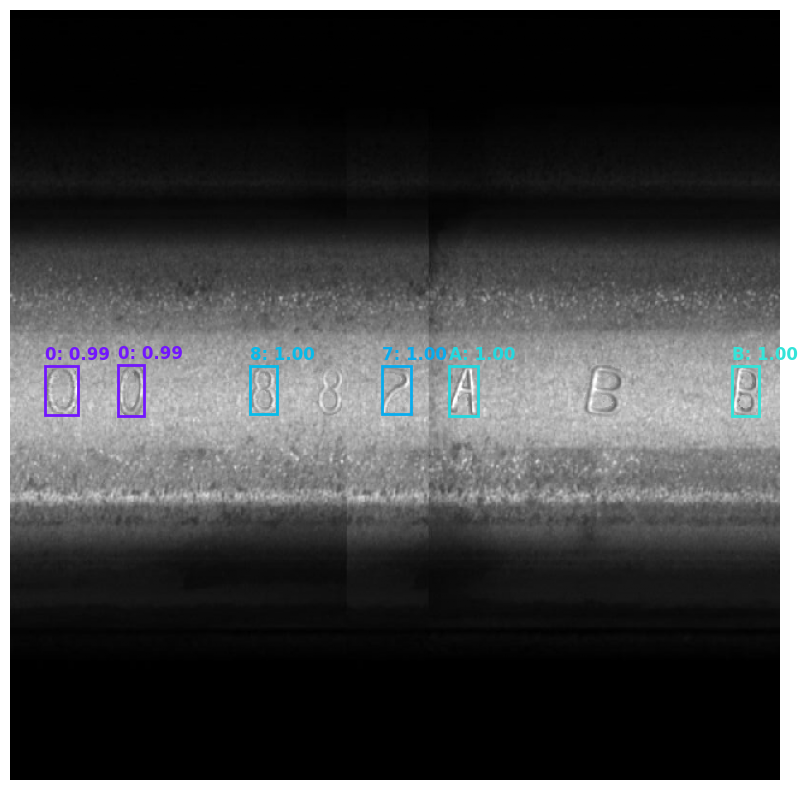

In [47]:
fold2 = r'D:\Projects\Rail_marking\data_gen_for_YOLO\generated_dataset\train'
# fold2 = r'D:\Projects\Rail_marking\data_gen_for_YOLO\dataset_cut\val'
# fold2 = r'D:\Projects\Rail_marking\data_gen_for_YOLO\dataset\val'
val_dataset = RailMarkDset(image_folder=fold2, label_folder=fold2)

model.eval()
detector = Detector()

with torch.no_grad():
    img, boxes, labels = val_dataset[17]
    # print(img.shape)
    img_batch = img.unsqueeze(0)
    img_batch = img_batch.cuda()

    loc, conf = model(img_batch)
    dets = detector.detect(loc, conf, conf_thresh=0.3)

    img_vis = img.squeeze().numpy()

    print(f"Ground truth boxes (norm): {boxes.tolist()}")
    print(f"Detections (norm): {dets[0].cpu().numpy()}")

    visualize_detections(img_vis, dets[0])

In [37]:
import os
from PIL import Image, ImageDraw, ImageFont

# Укажите путь к вашей папке со шрифтами
FONTS_DIR = r"D:\Projects\Rail_marking\data_gen_for_YOLO\fonts"
# Папка, куда сохранятся готовые картинки
OUTPUT_DIR = r"D:\Projects\Rail_marking\data_gen_for_YOLO\fonts"

# Создаем папку для результатов, если её нет
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Перебираем все файлы в папке со шрифтами
for filename in os.listdir(FONTS_DIR):
    if filename.lower().endswith(".ttf"):
        font_path = os.path.join(FONTS_DIR, filename)
        font_name = os.path.splitext(filename)[0]

        try:
            # Настраиваем размеры шрифта
            font_size_title = 24
            font_size_letter = 120

            # Загружаем шрифт для названия и для большой буквы
            font_title = ImageFont.truetype(font_path, font_size_title)
            font_letter = ImageFont.truetype(font_path, font_size_letter)

            # Создаем белое изображение (ширина 500px, высота 250px)
            img = Image.new("RGB", (500, 250), color="white")
            draw = ImageDraw.Draw(img)

            # Текст для вывода
            text_title = f"Font: {font_name}"
            text_letter = "J"

            # Рисуем название шрифта (черным цветом)
            draw.text((20, 20), text_title, fill="black", font=font_title)

            # Рисуем букву J по центру ниже
            draw.text((220, 80), text_letter, fill="black", font=font_letter)

            # Сохраняем картинку в формате PNG
            output_path = os.path.join(OUTPUT_DIR, f"{font_name}_preview.png")
            img.save(output_path)
            print(f"Успешно обработан: {filename}")

        except Exception as e:
            print(f"Ошибка при обработке {filename}: {e}")


Успешно обработан: ofont.ru_Blazma.ttf
Успешно обработан: ofont.ru_Casper.ttf
Успешно обработан: ofont.ru_Cuprum.ttf
Успешно обработан: ofont.ru_Droid Serif (1).ttf
Успешно обработан: ofont.ru_Droid Serif.ttf
Успешно обработан: ofont.ru_Glober.ttf
Успешно обработан: ofont.ru_GOST 26.008 _85.ttf
Успешно обработан: ofont.ru_GOST type A.ttf
Успешно обработан: ofont.ru_GOST type B.ttf
Успешно обработан: ofont.ru_Hirro Sans.ttf
Успешно обработан: ofont.ru_Moderustic.ttf
Успешно обработан: ofont.ru_Playfair Display.ttf
Успешно обработан: ofont.ru_Raleway.ttf
Успешно обработан: ofont.ru_Shonen.ttf
Успешно обработан: ofont.ru_Slimamif.ttf
Успешно обработан: ofont.ru_Ubuntu.ttf
Успешно обработан: ofont.ru_VDS.ttf
Успешно обработан: ofont.ru_X Typewriter.ttf
Успешно обработан: TGL_0-1451Eng.ttf


(640, 640, 1)


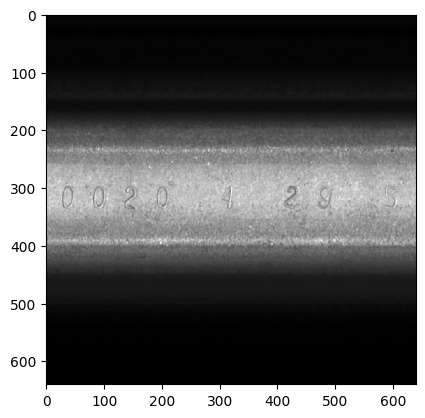

In [ ]:
# проверка аблументашнс

from torch.utils.data import DataLoader, Dataset
from utils import train_transform
from RailMarkDset import RailMarkDset, collate_fn
import matplotlib.pyplot as plt


fold1 = r'D:\Projects\Rail_marking\data_gen_for_YOLO\generated_dataset\train'
dataset = RailMarkDset(fold1, fold1, transform=train_transform)
dataloader = DataLoader(dataset=dataset, batch_size=2, collate_fn=collate_fn)

img, _ = next(iter(dataloader))
img = img[0]
img = img.permute(1, 2, 0)
img = img.numpy()

print(img.shape)

plt.imshow(img, cmap='gray')

In [65]:
# проверка конвертации разметки
import os
import cv2
from conv_yolo_label_2_ssd import yolo_to_corners

Labels_conv = []

fold = r'./test_val'
img = cv2.imread(os.path.join(fold, '0A_9A_91B_2.png'))
labels = []
with open(os.path.join(fold, '0A_9A_91B_2.txt')) as f:
    for line in f:
        parts = list(map(float, line.strip().split(' ')))
        x1, y1, x2, y2 = yolo_to_corners(*parts[1:], 640, 640)
        # x1, y1, x2, y2 = parts[1:]


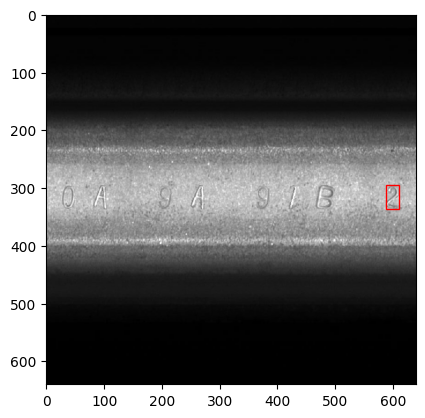

In [66]:
from matplotlib.patches import Rectangle

rect = Rectangle((x1, y1-1), x2 - x1, y2 - y1,
            linewidth=1, edgecolor='r', facecolor='none')


fig, ax = plt.subplots()
ax.add_patch(rect)
ax.imshow(img)
plt.show()


In [ ]:
# проверка на кроссвалидацию
import os
import numpy as np
from torch.utils.data import Dataset, DataLoader, Sampler


class DS(Dataset):
    def __init__(self, folder):
        self.file_names = [f for f in os.listdir(folder) if f.endswith('.txt')]

    def __len__(self):
        return len(self.file_names)

    def __getitem__(self, index):
        name = self.file_names[index]
        return name


class CVS(Sampler):
    def __init__(self, ds_idx, v_sz, valid=False):
        self.valid = valid
        if not self.valid:
            self.ds_idx = ds_idx
            self.v_sz = v_sz
        self.split_shuffle()

    def __len__(self):
        return len(self.ds_idx) - self.bord

    def split_shuffle(self):
        if not self.valid:
            self.bord = int(len(self.ds_idx) / self.v_sz)
            np.random.shuffle(self.ds_idx)
            self.res_idx = self.ds_idx[self.bord:]
            val_idx = self.ds_idx[:self.bord]
            np.save(r'./tmp/tmp_val_idx.npy', val_idx)
        else:
            self.res_idx = np.load(r'./tmp/tmp_val_idx.npy')

    def __iter__(self):
        yield from self.res_idx


In [51]:
np.load(r'./tmp/tmp_val_idx.npy')

array([15,  9, 11,  6])

In [48]:
folder = r'tmp'

ds = DS(folder)

tmp_s = CVS(np.arange(len(ds)), 5)
tmp_s_val = CVS(np.arange(len(ds)), 5, valid=True)

loader = DataLoader(dataset=ds, sampler=tmp_s, batch_size=4)
val_loader = DataLoader(dataset=ds, sampler=tmp_s_val, batch_size=4)

In [24]:
# on epoch end
tmp_s.split_shuffle()
tmp_s_val.split_shuffle()

In [49]:
for n in loader:
    print(n)
print('='*30)
for n in val_loader:
    print(n)


ff (1).txt
ff (14).txt
ff (16).txt
ff (10).txt
['ff (1).txt', 'ff (14).txt', 'ff (16).txt', 'ff (10).txt']
ff (11).txt
ff (9).txt
ff (7).txt
ff (8).txt
['ff (11).txt', 'ff (9).txt', 'ff (7).txt', 'ff (8).txt']
ff (17).txt
ff (6).txt
ff (3).txt
ff (20).txt
['ff (17).txt', 'ff (6).txt', 'ff (3).txt', 'ff (20).txt']
ff (19).txt
ff (13).txt
ff (12).txt
ff (4).txt
['ff (19).txt', 'ff (13).txt', 'ff (12).txt', 'ff (4).txt']
ff (5).txt
ff (18).txt
ff (2).txt
ff (15).txt
['ff (5).txt', 'ff (18).txt', 'ff (2).txt', 'ff (15).txt']
